# Vapour-Liquid Equilibrium

Speration processes that involves gas phase and liquid phase are governed by vapour-liquid equilibrium.

There are three cases of VLE problems:
* Bubble-point T calculation: Given liquid composition (xi) and pressure (P), determine the equilibrium temperature (T),
* Bubble-point P calculation: Given liquid composition (xi) and temperature (T), determine the equilibrium pressure (P),
* Dew-point T calculation: Given vapor composition (yi) and pressure (P), determine the equilibrium temperature (T),
* Dew-point P calculation: Given vapor composition (yi) and temperature (T), determine the equilibrium pressure (P).

In our applications, we usually assume the pressure to be constant, and then we can either either perform a bubble-T or a dew-T calculation. We will go ahead with bubble-T.

The governing set of conditions for the VLE are therefore:

1. VLE condition: Fugacities of each component must be equal in vapor and liquid phases
2. Ideal vapor assumption: Vapor phase fugacity coefficient = 1, simplifying the equilibrium
3. Bubble point formulation: Given liquid composition, solve for temperature and vapor composition
4. Degrees of freedom: With fixed pressure and given liquid composition, the system has 2 unknowns (T and vapor fractions) and 2 equations. However since these two are related (given T, y can be calculated and vice-versa, only one degree of freedom is present, e.g. the temperature)


Fugacity equality (general VLE condition):
\begin{equation*}
\hat{f}_i^V = \hat{f}_i^L
\end{equation*}

Vapor phase fugacity:
\begin{equation*}
\hat{f}_i^V = y_i \hat{\phi}_i P
\end{equation*}

Liquid phase fugacity:
\begin{equation*}
\hat{f}_i^L = x_i \hat{\gamma}_i P_i^{sat}
\end{equation*}

VLE equilibrium (ideal vapor phase):
\begin{equation*}
y_i = x_i \hat{\gamma}_i \frac{P_i^{sat}}{P}
\end{equation*}

Vapor composition normalization:
\begin{equation*}
\sum_i y_i = 1
\end{equation*}



Let us try the complete workflow:
1. define e.g. acetone-methanol system
2. calculate the pure component properties
3. determine the Antoine coefficients
4. perform the VLE routine

In [1]:
# imports to enable the notebook to access the src folder
import sys
import os
sys.path.append(os.path.dirname(os.getcwd()))

# import the necessary packages
from src.molecules import StructuralValidator
from src.pure import PropertyCalculator
from src.pure import AntoineCalculator
from src.data import load_unifac_data
from src.mixture.unifac.pyomo_vle import pyo_vle
import numpy as np
import matplotlib.pyplot as plt


In [2]:
# step1: define the compounds
mixture = {'acetone': {'CH3':1, 'CH3CO':1},
           'methanol': {'CH3OH':1}}
# validate the structures
validator = StructuralValidator()
validator.validate(mixture)

{'acetone': True, 'methanol': True}

In [3]:
# step2: calculate the required properties
prop_list = ['tc', 'pc', 'tb', 'ac']
pure_calc = PropertyCalculator()
pure_props = pure_calc.calculate(mixture, prop_list)
pure_props

{'acetone': {'tc': 490.113267330251,
  'pc': 48.803949995576296,
  'tb': 305.3729149261051,
  'ac': 0.33226923286882887},
 'methanol': {'tc': 513.0000000000005,
  'pc': 80.99999999999997,
  'tb': 337.84999999999985,
  'ac': 0.5639909999999987}}

In [4]:
# step3: calculate the Antoine coefficients
antoine_params = {}
antoine_calc = AntoineCalculator()
for compound, props in pure_props.items():
    results = antoine_calc.calculate_antoine_parameters(mixture, critical_properties=props)
    print('optimization results was', results['termination_condition'] )
    antoine_params[compound] = {}
    antoine_params[compound]['A'] = results['A']
    antoine_params[compound]['B'] = results['B']
    antoine_params[compound]['C'] = results['C']
antoine_params

optimization results was optimal
optimization results was optimal


{'acetone': {'A': 66.92258634247771,
  'B': 479242.884386997,
  'C': 6856.391918339008},
 'methanol': {'A': 5.253881516250653,
  'B': 1616.1411202945164,
  'C': -29.905956718707568}}

In [5]:
# step4: perform the vle

# define number of data points
n_data = 100
# set composition
x1 = np.linspace(0, 1, n_data)  # Component 1: 0 to 1
x2 = 1 - x1                     # Component 2: 1 to 0 (complement)
x = np.column_stack([x1, x2])  # Combine into 2D array
# provide nitial guess for temperature
# Extract boiling points
boiling_points = [props['tb'] for props in pure_props.values()]
T_min = min(boiling_points) 
T_max = max(boiling_points)  
T0 = np.linspace(T_min, T_max, n_data)
# Load all UNIFAC parameters
rk_data, qk_data, interaction_data = load_unifac_data()
# perform the VLE calculation
results, model = pyo_vle(x, T0, mixture, rk_data, qk_data, interaction_data, antoine_params, verbose=False)


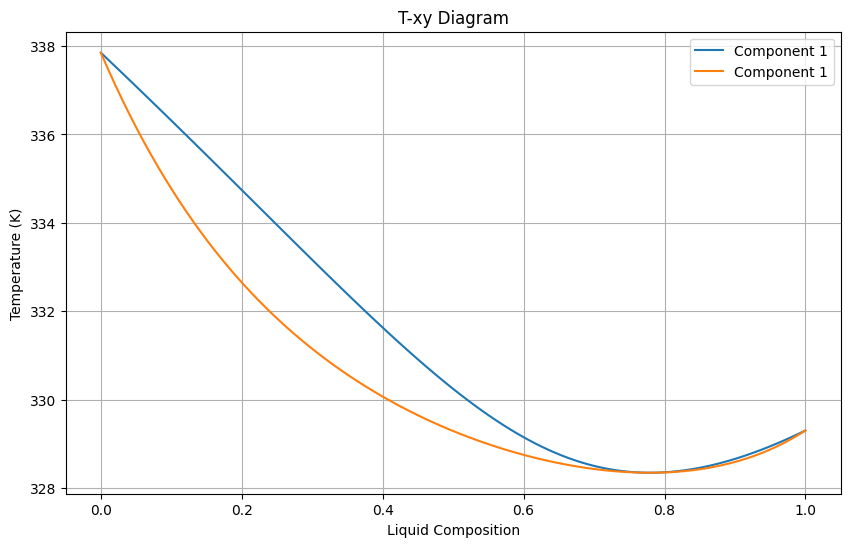

Gamma values:
Component 1: [1.88079404 1.85678185 1.83332628 1.81041408 1.78803234 1.76616845
 1.74481012 1.72394538 1.70356256 1.68365029 1.66419749 1.64519341
 1.62662754 1.60848968 1.59076989 1.57345852 1.55654617 1.54002369
 1.5238822  1.50811306 1.49270787 1.47765847 1.46295692 1.44859551
 1.43456674 1.42086335 1.40747826 1.39440459 1.38163568 1.36916504
 1.35698638 1.34509359 1.33348073 1.32214205 1.31107195 1.30026499
 1.28971592 1.27941962 1.26937112 1.25956562 1.24999844 1.24066505
 1.23156106 1.22268221 1.21402437 1.20558353 1.19735582 1.18933747
 1.18152485 1.17391442 1.16650277 1.15928659 1.15226268 1.14542794
 1.13877939 1.13231411 1.12602933 1.11992232 1.11399049 1.10823131
 1.10264235 1.09722127 1.0919658  1.08687377 1.08194309 1.07717174
 1.07255779 1.06809938 1.06379472 1.05964212 1.05563992 1.05178657
 1.04808057 1.0445205  1.04110499 1.03783277 1.03470261 1.03171333
 1.02886386 1.02615315 1.02358023 1.0211442  1.01884419 1.01667941
 1.01464914 1.01275268 1.01098943 1

In [11]:
# step5: lets plot the results in T-xy diagram and inspect the gamma values
import matplotlib.pyplot as plt

# Extract results
# retrieving the solutions
gamma_pyo = np.empty_like(x)
T_pyo = np.empty_like(T0)
y_pyo = np.empty_like(x)


for i in model.gamma.keys():
    gamma_pyo[i] = model.gamma[i].value

for i in model.T.keys():
    T_pyo[i] = model.T[i].value

for i in model.y.keys():
    y_pyo[i] = model.y[i].value

# Create T-xy plot
plt.figure(figsize=(10, 6))
#for i in range(x.shape[1]):
plt.plot(y_pyo[:, 0], T_pyo,  label=f'Component 1')
plt.plot(x[:, 0], T_pyo,  label=f'Component 1')
plt.ylabel('Temperature (K)')
plt.xlabel('Liquid Composition')
plt.title('T-xy Diagram')
plt.legend()
plt.grid()
plt.show()

# Inspect gamma values
print("Gamma values:")
for i in range(gamma_pyo.shape[1]):
    print(f"Component {i+1}: {gamma_pyo[:, i]}")

a good check is to see that the gammas are 1 at the edges of the compositions.

As you can see, there is no azeotrope between acetone and methanol, this is due to the wrong calculation of the pure component properties of acetone (namely the Tb, Tc and Pc). Therefore, we redefine these and redo the calculations using the experimental [data](https://webbook.nist.gov/cgi/cbook.cgi?ID=C67641&Units=SI&Mask=4#Thermo-Phase)

In [7]:
# fix the properties of acetone
pure_props['acetone']['tc'] = 508.1
pure_props['acetone']['pc'] = 48.0
pure_props['acetone']['tb'] = 329.3

Now we redo all the previous steps

In [12]:
# step3: calculate the Antoine coefficients
antoine_params = {}
antoine_calc = AntoineCalculator()
for compound, props in pure_props.items():
    results = antoine_calc.calculate_antoine_parameters(mixture, critical_properties=props)
    print('optimization results was', results['termination_condition'] )
    antoine_params[compound] = {}
    antoine_params[compound]['A'] = results['A']
    antoine_params[compound]['B'] = results['B']
    antoine_params[compound]['C'] = results['C']
antoine_params

optimization results was optimal
optimization results was optimal


{'acetone': {'A': 5.105487152022129,
  'B': 1863.5123768521207,
  'C': 36.111024354679266},
 'methanol': {'A': 5.253881516250653,
  'B': 1616.1411202945164,
  'C': -29.905956718707568}}

In [13]:
# step4: perform the vle

# provide nitial guess for temperature
# Extract boiling points
boiling_points = [props['tb'] for props in pure_props.values()]
T_min = min(boiling_points) 
T_max = max(boiling_points)  
T0 = np.linspace(T_min, T_max, n_data)
# Load all UNIFAC parameters
rk_data, qk_data, interaction_data = load_unifac_data()
# perform the VLE calculation
results, model = pyo_vle(x, T0, mixture, rk_data, qk_data, interaction_data, antoine_params, verbose=False)

# 

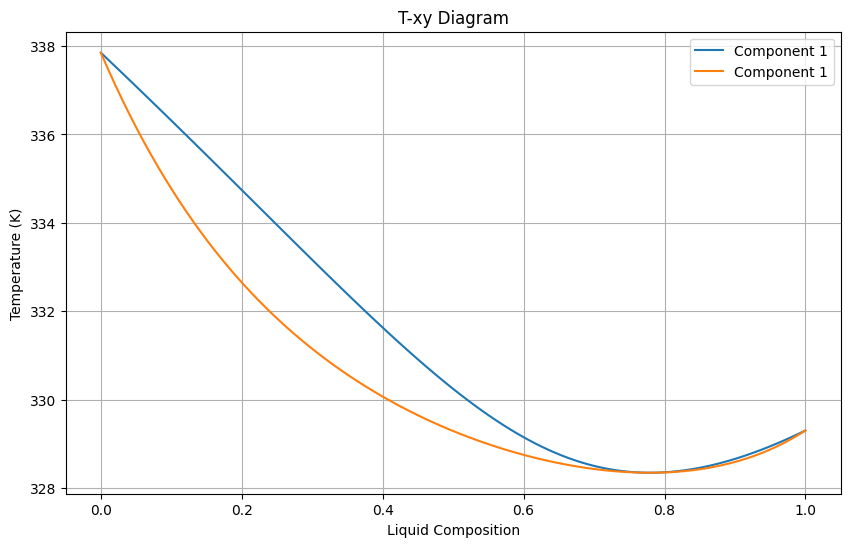

Gamma values:
Component 1: [1.88079404 1.85678185 1.83332628 1.81041408 1.78803234 1.76616845
 1.74481012 1.72394538 1.70356256 1.68365029 1.66419749 1.64519341
 1.62662754 1.60848968 1.59076989 1.57345852 1.55654617 1.54002369
 1.5238822  1.50811306 1.49270787 1.47765847 1.46295692 1.44859551
 1.43456674 1.42086335 1.40747826 1.39440459 1.38163568 1.36916504
 1.35698638 1.34509359 1.33348073 1.32214205 1.31107195 1.30026499
 1.28971592 1.27941962 1.26937112 1.25956562 1.24999844 1.24066505
 1.23156106 1.22268221 1.21402437 1.20558353 1.19735582 1.18933747
 1.18152485 1.17391442 1.16650277 1.15928659 1.15226268 1.14542794
 1.13877939 1.13231411 1.12602933 1.11992232 1.11399049 1.10823131
 1.10264235 1.09722127 1.0919658  1.08687377 1.08194309 1.07717174
 1.07255779 1.06809938 1.06379472 1.05964212 1.05563992 1.05178657
 1.04808057 1.0445205  1.04110499 1.03783277 1.03470261 1.03171333
 1.02886386 1.02615315 1.02358023 1.0211442  1.01884419 1.01667941
 1.01464914 1.01275268 1.01098943 1

In [14]:
# step5: lets plot the results in T-xy diagram and inspect the gamma values

# Extract results
# retrieving the solutions
gamma_pyo = np.empty_like(x)
T_pyo = np.empty_like(T0)
y_pyo = np.empty_like(x)


for i in model.gamma.keys():
    gamma_pyo[i] = model.gamma[i].value

for i in model.T.keys():
    T_pyo[i] = model.T[i].value

for i in model.y.keys():
    y_pyo[i] = model.y[i].value

# Create T-xy plot
plt.figure(figsize=(10, 6))
#for i in range(x.shape[1]):
plt.plot(y_pyo[:, 0], T_pyo,  label=f'Component 1')
plt.plot(x[:, 0], T_pyo,  label=f'Component 1')
plt.ylabel('Temperature (K)')
plt.xlabel('Liquid Composition')
plt.title('T-xy Diagram')
plt.legend()
plt.grid()
plt.show()

# Inspect gamma values
print("Gamma values:")
for i in range(gamma_pyo.shape[1]):
    print(f"Component {i+1}: {gamma_pyo[:, i]}")